# Hydrological Analysis of a DEM

*Section 8 — Hydrology, notebook 1 of 1.* Previous: `07_spectral_analysis/03_spectral_unmixing`. Next: `09_tile_graph_workflows/01_indices_classification_filtering`.

**You will learn:**
- why a DEM must be hydrologically conditioned, and how filling and breaching depressions differ;
- how to calculate flow directions (D8, D-Infinity and MFD) and flow accumulation;
- how to extract a stream network, order it (Strahler) and convert it to vector lines;
- how to delineate the watersheds above pour points (river mouths and gauging stations), drainage basins and reach subcatchments, and convert them to polygons with their areas;
- how to trace flow paths downstream and upstream from points;
- how to calculate the height above nearest drainage (HAND), map a simple flood scenario and calculate the topographic wetness index (TWI), stream power index (SPI) and RUSLE LS factor;
- how to map rasters shaded by a hillshade with `rsgispy.mapping.raster.create_shaded_cmap_img_map` and `add_hillshade`.

**Before you start:** section 2 introduces the `rsgispy.mapping` functions used for the maps here; no other notebook needs to have been run.

**Data:** `../data/dem_10m_osgb.tif` (a 10 m DEM around Aberystwyth, covering the Rheidol and Ystwyth valleys; British National Grid, EPSG:27700). The pour points are created in the notebook. Outputs are written to `outputs/hydrology/`.

**Run time:** about 2 minutes.

## Background

Water flows downhill, so a digital elevation model (DEM) holds most of the information needed to work out where water goes across a landscape: which way it flows from each pixel, how much area drains through each pixel, where the streams are, which area drains to a point on a river (its watershed or catchment) and which parts of the landscape are wet, prone to erosion or close to the river and likely to flood.

The hydrological tools in rsgispy are in `rsgispy.elevation.hydrology`. They follow a standard workflow, which this notebook works through:

1. **Condition the DEM** so that water can flow off it (remove the pits and depressions).
2. **Route the flow**: a flow direction for every pixel and the flow accumulation (upslope area) from it.
3. **Extract the streams** (pixels with a large upslope area) and order them.
4. **Delineate catchments**: above pour points, whole drainage basins and the subcatchment of each stream reach.
5. **Terrain indices** derived from the flow routing: HAND, flood depth, TWI, SPI and LS.

The DEM covers about 37 x 37 km of west Wales: Aberystwyth on the coast, the Rheidol and Ystwyth valleys running west from the Pumlumon (Plynlimon) uplands, the Clarach valley to the north of Aberystwyth and the Cors Fochno bog and Dyfi estuary in the north.

All the hydrology functions need a raster in a **projected coordinate reference system with units of metres** (they measure slopes, lengths and areas). The DEM is on the British National Grid, so it can be used as it is; a DEM in latitude and longitude would first need reprojecting with `rsgispy.imageutils.warp.reproject_image` (with bilinear interpolation).

The functions read the whole raster into memory (flow routing is not a local operation, so it cannot be done in blocks) and most of them are compiled with `numba`: the first call of each function compiles it, which takes a few seconds, and later calls are fast. The DEM here has 14 million pixels, which is small enough to process in one go on a laptop, so it is not subset.

**RSGISLib users:** RSGISLib had no hydrology module of its own (it relied on other tools, such as TauDEM or WhiteboxTools, for this). The rsgispy functions read and write GeoTIFFs (or any other raster format) like the rest of rsgispy.

## Running Notebook

The notebook has been run and saved with the outputs so you can see what the outputs should be and so the notebook can be browsed online without having to run the notebook for it to make sense.

If you are running the notebook for yourself it is recommended that you clear the existing outputs which can be done by running one of the following options depending on what system you are using:

**Jupyter-lab**:

> \> _Edit_ \> _'Clear All Outputs'_

**Jupyter-notebook**:

> \> _Cell_ \> _'All Outputs'_ \> _Clear_

# 1. Import Modules

In [1]:
import os
import time

import geopandas
import matplotlib
import matplotlib.pyplot as plt
import numpy
import pandas
import rasterio
import rsgispy
import rsgispy.elevation.hydrology
import rsgispy.elevation.illumination
import rsgispy.elevation.terrain
import rsgispy.imagecalc.maths
import rsgispy.imagecalc.stats
import rsgispy.imageutils.metadata
import rsgispy.mapping.elements
import rsgispy.mapping.raster
import rsgispy.mapping.vector
from rsgispy.imagecalc.maths import BandDefn

# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

# Time the whole notebook.
nb_start_time = time.time()

# 2. Define Input File and Output Directory

In [2]:
# The input DEM is only read, so it is used directly from the data directory.
input_dem = "../data/dem_10m_osgb.tif"

out_dir = os.path.join("outputs", "hydrology")
os.makedirs(out_dir, exist_ok=True)

# 3. Preparing the DEM

## 3.1 Checking the DEM

Before starting it is worth checking the DEM: is the coordinate system projected and in metres, is a no data value set, and is the range of elevations sensible?

In [3]:
with rasterio.open(input_dem) as src:
    print(f"CRS: {src.crs.to_string()} (projected: {src.crs.is_projected}, "
          f"units: {src.crs.linear_units})")
    print(f"Size: {src.width} x {src.height} pixels; no data value: {src.nodata}")

x_res, y_res = rsgispy.imageutils.metadata.get_img_res(input_dem, abs_vals=True)
pxl_area = x_res * y_res
z_min, z_max, z_mean, _ = rsgispy.imagecalc.stats.calc_basic_img_band_stats(
    input_dem, use_pbar=False
)
print(f"Pixel size: {x_res:.0f} x {y_res:.0f} m; elevation {z_min[0]:.1f} to "
      f"{z_max[0]:.1f} m (mean {z_mean[0]:.1f} m)")

CRS: EPSG:27700 (projected: True, units: metre)
Size: 3726 x 3757 pixels; no data value: -32768.0


Pixel size: 10 x 10 m; elevation 0.0 to 750.4 m (mean 270.3 m)


## 3.2 Setting the Sea to No Data

The minimum elevation is 0 m: the sea in this DEM is not no data but has an elevation of 0, and it covers about 8% of the image. This matters for hydrology. A large flat area at 0 m is treated as land: all the rivers would drain into it and then wander across it to the edge of the image, so the coastline would not be the outlet of the rivers. The sea is therefore set to no data with `band_maths` (pixels at or below 0 m become -32768, the DEM's no data value). The hydrology functions treat no data pixels as the outside of the DEM, so water leaves the DEM where it reaches the coast.

The same applies to any DEM: check how voids, the sea and lakes are coded before conditioning.

In [4]:
dem_img = os.path.join(out_dir, "dem_10m_land.tif")
dem_no_data = -32768

rsgispy.imagecalc.maths.band_maths(
    dem_img,
    f"dem <= 0 ? {dem_no_data} : dem",
    [BandDefn("dem", input_dem, 1)],
    datatype=rsgispy.TYPE_32FLOAT,
    no_data_val=dem_no_data,
    use_pbar=False,
)

with rasterio.open(dem_img) as src:
    dem_arr = src.read(1)
vld_dem = dem_arr != dem_no_data
n_vld_pxls = int(numpy.count_nonzero(vld_dem))
print(f"{100 * (1 - vld_dem.mean()):.1f}% of the pixels are now no data (the sea)")
print(f"Land area: {n_vld_pxls * pxl_area / 1e6:.1f} km2")

7.9% of the pixels are now no data (the sea)
Land area: 1288.6 km2


## 3.3 Hillshade

A hillshade is a useful background for hydrological maps as it shows the shape of the terrain. `rsgispy.elevation.illumination.hillshade` is given the position of the sun: from the north-west (an `azimuth` of 315°) at 45° from the vertical (`zenith`).

Most of the maps in this notebook are drawn with `rsgispy.mapping.raster.create_shaded_cmap_img_map`: it draws a raster with a colour map (`create_raster_cmap_img_map`) and then the hillshade on top of it with some transparency (`add_hillshade`, with `hshade_alpha` setting the transparency), so the colours are shaded by the terrain. It also adds a scale bar, a north arrow and a colour bar (`cbar_label`), and returns the colour-mapped image (its colour bar is `img.colorbar`). The hillshade can be given as an image (`hshade_img`, as here, as it is used for many maps) or made in memory for the map's extent from the DEM (`dem_img=...`).

The images are resampled on their values (`interp_stage="data"`, the default of the rsgispy raster maps) rather than on their colours, so narrow features such as one-pixel-wide channels stay visible when a large raster is drawn on a small map.

`add_hillshade` can also be used on its own, to shade any map already drawn on an axis (for example a thematic map).

In [5]:
hshade_img = os.path.join(out_dir, "hillshade.tif")
rsgispy.elevation.illumination.hillshade(
    dem_img, hshade_img, azimuth=315.0, zenith=45.0, use_pbar=False
)

# The bounding box of the whole DEM (MinX, MaxX, MinY, MaxY)
dem_bbox = rsgispy.imageutils.metadata.get_img_bbox(dem_img)

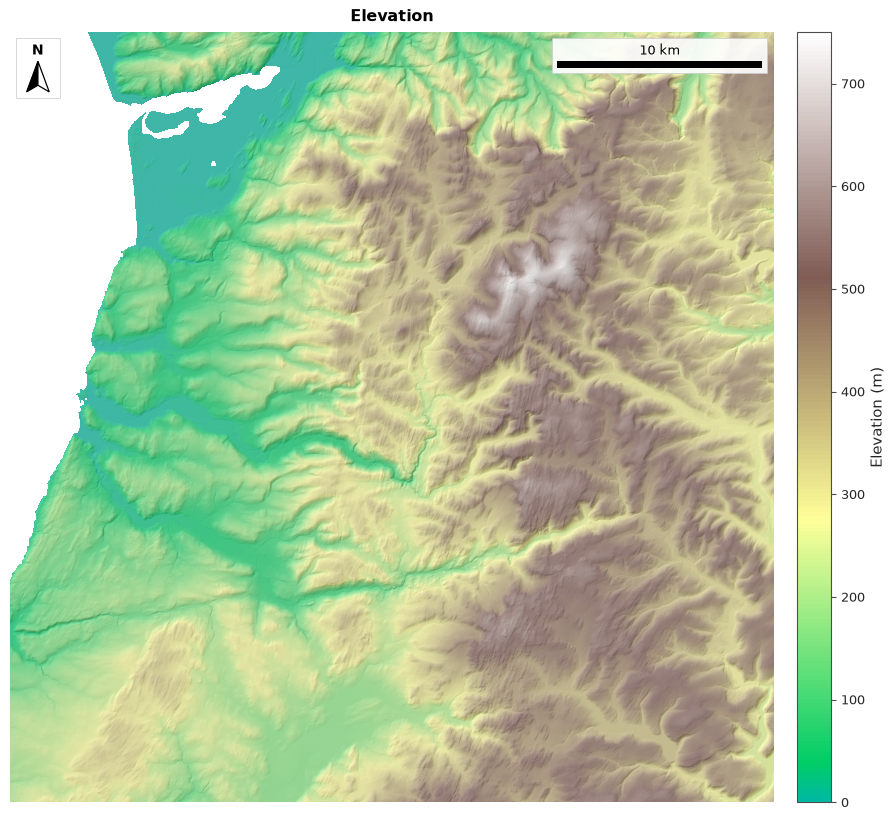

In [6]:
fig, ax = plt.subplots(figsize=(10, 10))
# The 'terrain' colour map starts with blues for the sea, so the colours are
# stretched from -200 m to keep the land in greens and browns; the colour bar
# is then cut to the range of the land.
img = rsgispy.mapping.raster.create_shaded_cmap_img_map(
    ax, dem_img, hshade_img, bbox=dem_bbox, title_str="Elevation", cmap_name="terrain",
    vmin=-200, vmax=750, hshade_alpha=0.35, cbar_label="Elevation (m)",
)
_ = img.colorbar.ax.set_ylim(0, 750)

# 4. Conditioning the DEM

## 4.1 Why Condition the DEM?

A raw DEM is not *hydrologically correct*. It contains pits and closed depressions (sinks): pixels or groups of pixels that are lower than all their neighbours, so water flowing into them has no way out. Some are real (lakes, quarries, peat bog pools), but most are artefacts: noise in the elevations, bridges and road embankments that cross a valley and act as dams in the DEM, and flat areas such as water surfaces. Every flow path that reaches a sink ends there, so without conditioning the streams stop part of the way down the valleys and the catchments are broken into pieces.

## 4.2 Finding the Sinks

Before changing the DEM it is worth looking at what conditioning will change. `identify_sinks` labels each sink with an ID (`1..K`; `0` where there is no sink and `-1` on no data) and, with `output_depth_img`, writes how far each pixel is below the level at which its sink spills over (metres).

In [7]:
sinks_img = os.path.join(out_dir, "sinks.tif")
sink_depth_img = os.path.join(out_dir, "sink_depth.tif")
rsgispy.elevation.hydrology.identify_sinks(
    dem_img, sinks_img, output_depth_img=sink_depth_img, use_pbar=False
)

with rasterio.open(sinks_img) as src:
    sink_ids = src.read(1)
with rasterio.open(sink_depth_img) as src:
    sink_depth = src.read(1)

n_sinks = int(sink_ids.max())
# The number of pixels and maximum depth of each sink
sink_n_pxls = numpy.bincount(sink_ids[sink_ids > 0], minlength=n_sinks + 1)[1:]
sink_max_depth = numpy.zeros(n_sinks + 1)
numpy.maximum.at(sink_max_depth, sink_ids[sink_ids > 0], sink_depth[sink_ids > 0])
sink_max_depth = sink_max_depth[1:]

print(f"{n_sinks} sinks covering {sink_n_pxls.sum()} pixels "
      f"({100 * sink_n_pxls.sum() / n_vld_pxls:.1f}% of the land)")
print(f"{numpy.count_nonzero(sink_n_pxls == 1)} sinks are a single pixel and "
      f"{numpy.count_nonzero(sink_max_depth < 0.5)} are less than 0.5 m deep")
print(f"{numpy.count_nonzero(sink_max_depth > 2)} sinks are more than 2 m deep; "
      f"the deepest is {sink_max_depth.max():.2f} m")

21887 sinks covering 270128 pixels (2.1% of the land)
7889 sinks are a single pixel and 20535 are less than 0.5 m deep
111 sinks are more than 2 m deep; the deepest is 8.74 m


Most of the sinks are tiny and shallow: noise in the DEM. A few are large or deep and need a closer look. Below, the sinks are mapped for the north of the DEM, around Borth and the Cors Fochno raised bog, where the land is very flat and there are many large, shallow sinks. The largest sink in the DEM (about 1.7 km²) is the Nant-y-moch reservoir in the Pumlumon uplands, a real lake; the deepest (8.7 m) is close to Llyn Llygad Rheidol, a corrie lake below the summit of Pumlumon Fawr.

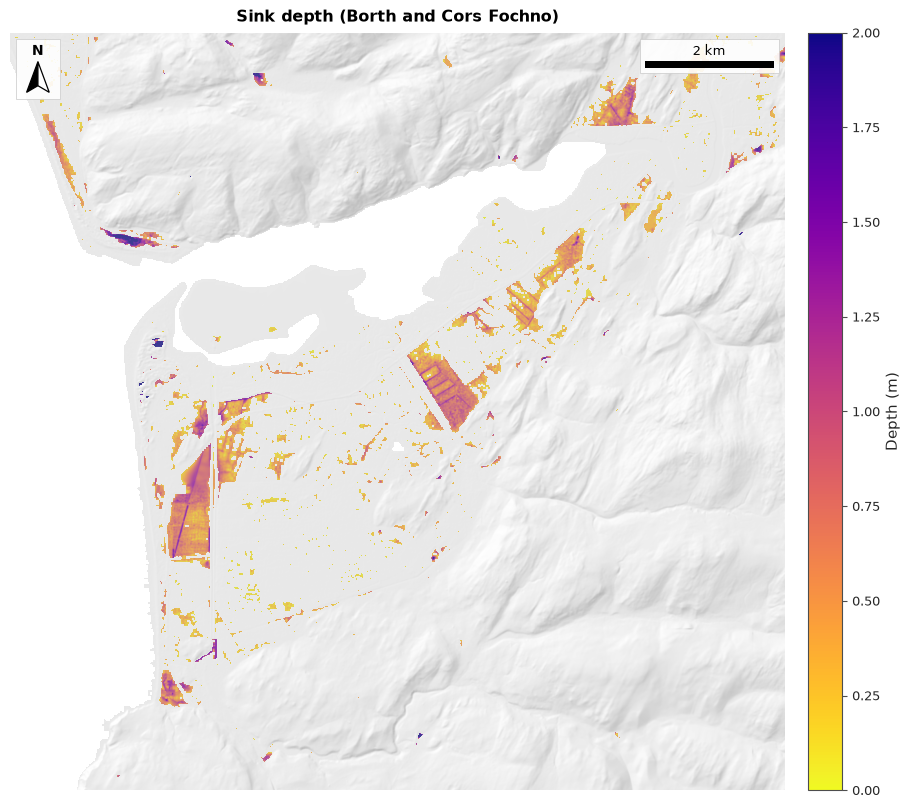

In [8]:
# A zoom over Borth, Cors Fochno and the Dyfi estuary.
borth_bbox = [258500, 270500, 287500, 299230]

# Show only the sink pixels: the other pixels are set to no data.
sink_depth_disp_img = os.path.join(out_dir, "sink_depth_display.tif")
rsgispy.imagecalc.maths.band_maths(
    sink_depth_disp_img,
    "depth > 0 ? depth : -1",
    [BandDefn("depth", sink_depth_img, 1)],
    datatype=rsgispy.TYPE_32FLOAT,
    no_data_val=-1,
    use_pbar=False,
)

fig, ax = plt.subplots(figsize=(10, 10))
img = rsgispy.mapping.raster.create_shaded_cmap_img_map(
    ax, sink_depth_disp_img, hshade_img, bbox=borth_bbox,
    title_str="Sink depth (Borth and Cors Fochno)", cmap_name="plasma_r", vmin=0, vmax=2,
    hshade_alpha=0.3, cbar_label="Depth (m)",
)

## 4.3 Filling and Breaching

There are two ways to remove a sink:

* **Filling** (`fill_depressions`, the Priority-Flood algorithm of Barnes et al., 2014) raises every pixel in a sink to the level of its lowest outlet (its spill point). The DEM is only ever raised, and each filled sink becomes a flat "lake" surface. Large fills, for example behind a road embankment across a valley, turn the valley into a flat where the direction of the flow is arbitrary.
* **Breaching** (`breach_depressions`, the least-cost method of Lindsay, 2016) cuts a channel from the bottom of the sink through the barrier to lower ground. The DEM is only ever lowered; fewer pixels change and the cut is usually where the real river crosses the barrier, but without limits breaching can cut deep, long trenches through real barriers.

`condition_dem` combines them (`method="breach_and_fill"`, the default): it breaches only where the cut is at most `max_breach_depth` metres deep and at most `max_breach_length` pixels long, and fills whatever is left. The limits are chosen from the barriers expected in the landscape: road and rail embankments and bridges are typically 2–10 m high and a few tens of metres wide, so a maximum depth of 5 m and a maximum length of 30 pixels (300 m at 10 m) are used here.

`condition_dem` can also burn mapped rivers into the DEM (`streams_vec`) before breaching; see section 6.5.

The DEM is filled, breached (without limits) and conditioned with `condition_dem` below so the three can be compared; the conditioned DEM is used from here on. This takes about a minute.

In [9]:
filled_img = os.path.join(out_dir, "dem_filled.tif")
breached_img = os.path.join(out_dir, "dem_breached.tif")
cond_dem = os.path.join(out_dir, "dem_cond.tif")

# For comparison: fill all the sinks, or breach all the sinks (no limits).
rsgispy.elevation.hydrology.fill_depressions(dem_img, filled_img, use_pbar=False)
rsgispy.elevation.hydrology.breach_depressions(dem_img, breached_img, use_pbar=False)

# The DEM used from here on: breach shallow, short obstructions and fill the rest.
rsgispy.elevation.hydrology.condition_dem(
    dem_img,
    cond_dem,
    method="breach_and_fill",
    max_breach_depth=5.0,  # metres
    max_breach_length=30,  # pixels
    use_pbar=False,
)

## 4.4 Comparing the Conditioned DEMs

The difference between each conditioned DEM and the original is calculated with `band_maths` (positive where pixels were raised by filling, negative where they were lowered by breaching) and summarised.

In [10]:
diff_imgs = dict()
change_stats = []
for name, c_img in (("fill", filled_img), ("breach", breached_img),
                    ("condition_dem", cond_dem)):
    diff_img = os.path.join(out_dir, f"dem_diff_{name}.tif")
    rsgispy.imagecalc.maths.band_maths(
        diff_img,
        f"raw == {dem_no_data} ? {dem_no_data} : cond - raw",
        [BandDefn("raw", dem_img, 1), BandDefn("cond", c_img, 1)],
        datatype=rsgispy.TYPE_32FLOAT,
        no_data_val=dem_no_data,
        use_pbar=False,
    )
    diff_imgs[name] = diff_img
    with rasterio.open(diff_img) as src:
        diff = src.read(1)[vld_dem]
    change_stats.append({
        "method": name,
        "raised_pxls": int(numpy.count_nonzero(diff > 0.001)),
        "lowered_pxls": int(numpy.count_nonzero(diff < -0.001)),
        "changed_pct": 100 * numpy.count_nonzero(numpy.abs(diff) > 0.001) / n_vld_pxls,
        "max_raise_m": float(diff.max()),
        "max_cut_m": float(-diff.min()),
    })
change_stats = pandas.DataFrame(change_stats).set_index("method")
change_stats.round(2)

,raised_pxls,lowered_pxls,changed_pct,max_raise_m,max_cut_m
method,,,,,
fill,268205,0,2.08,8.74,-0.00
breach,0,81604,0.63,0.00,8.82
condition_dem,37781,70244,0.84,8.74,6.39


How to read the table:

* **Filling** changed the most pixels (about 2% of the land), all by raising them; no pixel was raised by more than the depth of the deepest sink.
* **Breaching** changed far fewer pixels (about 0.6% of the land), all by lowering them. Without limits every sink is breached, along the path that needs the least cutting to lower ground, the coast or the edge of the DEM. Here the deepest cut is about 8.8 m, where the corrie below Pumlumon Fawr (the deepest sink) is drained through its rim, and only 69 pixels are cut by more than 5 m. On this DEM the unconstrained cuts are therefore shallow, but behind a real barrier (a dam, a road embankment across a valley or a deep quarry) unconstrained breaching cuts a deep, long trench through it. This is why the breach limits matter.
* **`condition_dem`** changed less than half as many pixels as filling, mostly by breaching, and no cut is deeper than about 6 m (the 5 m limit plus the small gradient given to the channel). The sinks that could not be breached within the limits (the reservoir, the bog pools and the corrie lake) were filled.

The maps below show the differences for the area around Borth: the filled DEM has large raised areas over the bog, while the conditioned DEM is mostly breached with short channels.

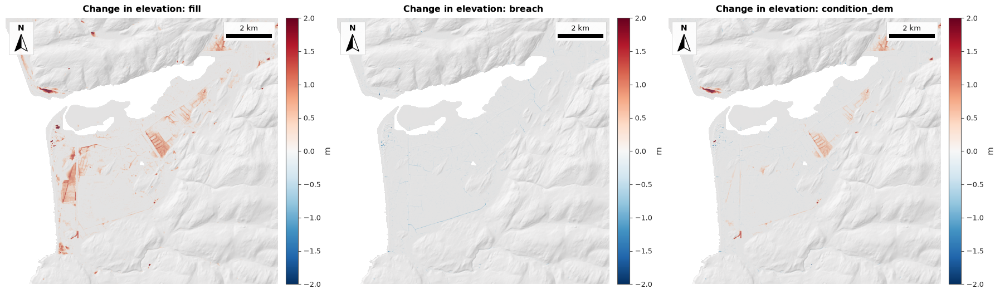

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
for ax, name in zip(axs, ["fill", "breach", "condition_dem"]):
    rsgispy.mapping.raster.create_shaded_cmap_img_map(
        ax, diff_imgs[name], hshade_img, bbox=borth_bbox,
        title_str=f"Change in elevation: {name}", cmap_name="RdBu_r", vmin=-2, vmax=2,
        hshade_alpha=0.3, cbar_label="m",
    )
plt.tight_layout()

## 4.5 Flat Areas

Filling leaves flat surfaces, where no pixel is lower than its neighbours. `resolve_flats` shows where they are: it writes the flat gradient of Barnes et al. (2014), `0` on sloping pixels and positive values on flats, which decrease towards the flat's outlet. It does not need to be applied before routing the flow: `flow_direction` routes water across flats in the same way (`flat_routing=True`, the default), towards the outlet and away from higher ground.

In [12]:
flats_img = os.path.join(out_dir, "flats_gradient_filled.tif")
rsgispy.elevation.hydrology.resolve_flats(filled_img, flats_img, use_pbar=False)
with rasterio.open(flats_img) as src:
    n_flat = int(numpy.count_nonzero(src.read(1) > 0))
print(f"Filled DEM: {n_flat} flat pixels ({n_flat * pxl_area / 1e6:.1f} km2)")

Filled DEM: 345011 flat pixels (34.5 km2)


# 5. Flow Routing

## 5.1 Flow Direction

`flow_direction` calculates, for every pixel, where its water goes. There are three methods:

* `"d8"`: all the water goes to the steepest of the eight neighbours. The output is a `uint8` code for the direction: `1` (east), `2` (south-east), `4` (south), `8` (south-west), `16` (west), `32` (north-west), `64` (north), `128` (north-east), and `0` where water leaves the DEM. D8 gives a single path from every pixel, so it is needed for streams, catchments, flow paths and HAND, and those functions require it.
* `"dinf"`: D-Infinity (Tarboton, 1997). The direction is a continuous angle (radians anticlockwise from east) and the water is split between the two neighbours either side of it.
* `"mfd"`: multiple flow direction (Quinn et al., 1991). The water is split between all the downslope neighbours in proportion to `slope ** mfd_exponent`; the output has 8 bands of fractions. A larger exponent concentrates the flow towards the steepest neighbour.

All three are calculated below. Each takes a few seconds (plus the compilation the first time).

In [13]:
fdir_d8 = os.path.join(out_dir, "flow_dir_d8.tif")
fdir_dinf = os.path.join(out_dir, "flow_dir_dinf.tif")
fdir_mfd = os.path.join(out_dir, "flow_dir_mfd.tif")

rsgispy.elevation.hydrology.flow_direction(cond_dem, fdir_d8, method="d8", use_pbar=False)
rsgispy.elevation.hydrology.flow_direction(cond_dem, fdir_dinf, method="dinf",
                                           use_pbar=False)
rsgispy.elevation.hydrology.flow_direction(
    cond_dem, fdir_mfd, method="mfd", mfd_exponent=1.1, use_pbar=False
)

with rasterio.open(fdir_d8) as src:
    d8_codes, d8_counts = numpy.unique(src.read(1), return_counts=True)
print("D8 codes and number of pixels:")
print(dict(zip(d8_codes.tolist(), d8_counts.tolist())))
with rasterio.open(fdir_mfd) as src:
    print(f"MFD directions: {src.count} bands")

D8 codes and number of pixels:
{0: 2394, 1: 1294984, 2: 1551829, 4: 1797761, 8: 1515279, 16: 1670798, 32: 1777719, 64: 1975501, 128: 1299901, 255: 1112416}
MFD directions: 8 bands


The D8 codes are spread fairly evenly across the eight directions; `0` marks the pixels where water leaves the DEM (at the coast and the edges) and `255` is the no data value (the sea).

To compare D8 and D-Infinity, both are converted to angles in degrees (anticlockwise from east) with `band_maths` and mapped for a small area of the upper Rheidol valley, around Ponterwyd, with a cyclic colour map. D8 can only take eight values, so smooth hillslopes are broken into blocks of a single direction, while the D-Infinity angle changes smoothly with the shape of the slope.

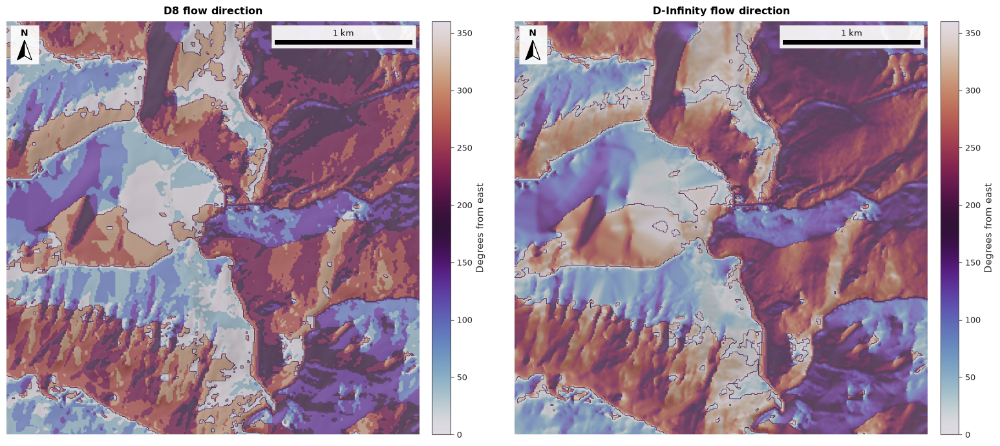

In [14]:
fdir_d8_deg = os.path.join(out_dir, "flow_dir_d8_degrees.tif")
fdir_dinf_deg = os.path.join(out_dir, "flow_dir_dinf_degrees.tif")

# D8 codes to angles anticlockwise from east (-1 = no direction).
d8_exp = "-1"
for d8_code, d8_ang in ((1, 0), (2, 315), (4, 270), (8, 225), (16, 180), (32, 135),
                        (64, 90), (128, 45)):
    d8_exp = f"d8 == {d8_code} ? {d8_ang} : ({d8_exp})"
rsgispy.imagecalc.maths.band_maths(
    fdir_d8_deg, d8_exp, [BandDefn("d8", fdir_d8, 1)], datatype=rsgispy.TYPE_32FLOAT,
    no_data_val=-1, use_pbar=False,
)
# D-Infinity radians to degrees (negative values are flats, outlets or no data).
rsgispy.imagecalc.maths.band_maths(
    fdir_dinf_deg, "ang < 0 ? -1 : ang * 57.29578", [BandDefn("ang", fdir_dinf, 1)],
    datatype=rsgispy.TYPE_32FLOAT, no_data_val=-1, use_pbar=False,
)

hill_bbox = [273000, 276000, 280500, 283500]
fig, axs = plt.subplots(1, 2, figsize=(16, 7))
for ax, (title, deg_img) in zip(axs, (("D8 flow direction", fdir_d8_deg),
                                     ("D-Infinity flow direction", fdir_dinf_deg))):
    rsgispy.mapping.raster.create_shaded_cmap_img_map(
        ax, deg_img, hshade_img, bbox=hill_bbox, title_str=title, cmap_name="twilight",
        vmin=0, vmax=360, hshade_alpha=0.3, cbar_label="Degrees from east",
    )
plt.tight_layout()

## 5.2 Flow Accumulation

`flow_accumulation` detects the routing method from its input and sums the upslope area draining through each pixel, as a number of pixels (`out_units="cells"`, the default) or as an area in m² (`out_units="area"`). Areas are used here so the results do not depend on the pixel size. The units are recorded in the output file, so the functions that read the accumulation (such as `extract_streams`) know what they are.

The accumulation is calculated from all three flow directions. The D8 accumulation is used for the streams and catchments and the MFD accumulation for the terrain indices (section 8.3).

A useful check of the routing is that no water is lost: the accumulation at the pixels where water leaves the DEM (D8 code `0`) must add up to the area of the land.

In [15]:
facc_d8 = os.path.join(out_dir, "flow_acc_d8.tif")
facc_dinf = os.path.join(out_dir, "flow_acc_dinf.tif")
facc_mfd = os.path.join(out_dir, "flow_acc_mfd.tif")
for fdir_img, facc_img in ((fdir_d8, facc_d8), (fdir_dinf, facc_dinf), (fdir_mfd, facc_mfd)):
    rsgispy.elevation.hydrology.flow_accumulation(
        fdir_img, facc_img, out_units="area", use_pbar=False
    )

with rasterio.open(fdir_d8) as src:
    outlets = src.read(1) == 0
print(f"Land area: {n_vld_pxls * pxl_area / 1e6:.1f} km2")
for name, facc_img in (("D8", facc_d8), ("D-Infinity", facc_dinf), ("MFD", facc_mfd)):
    with rasterio.open(facc_img) as src:
        acc = src.read(1)
    print(f"{name}: largest contributing area {acc.max() / 1e6:.1f} km2; "
          f"total at the outlets {acc[outlets].sum() / 1e6:.1f} km2")

Land area: 1288.6 km2
D8: largest contributing area 193.3 km2; total at the outlets 1288.6 km2
D-Infinity: largest contributing area 193.2 km2; total at the outlets 1288.6 km2


MFD: largest contributing area 193.1 km2; total at the outlets 1288.6 km2


All three methods route all the water off the DEM, and the largest contributing area (the Ystwyth at the coast) is the same for all three: the same rivers reach the coast whichever way the water is split on the hillslopes.

The flow accumulation is extremely skewed (from 100 m² on the ridges to nearly 200 km² at the river mouths), so it is mapped with a logarithmic colour scale; areas below 1 ha are left white. The rivers appear as continuous lines that end at the coast or the edge of the DEM. Lines that stopped in the middle of a valley would show a sink that had not been removed.

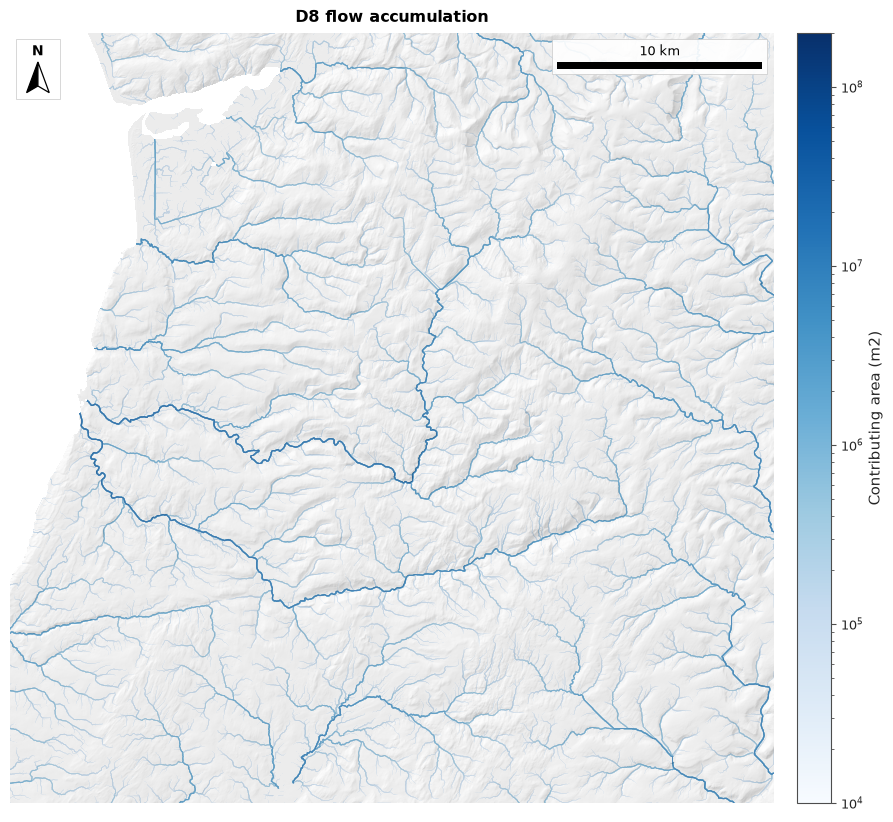

In [16]:
fig, ax = plt.subplots(figsize=(10, 10))
img = rsgispy.mapping.raster.create_shaded_cmap_img_map(
    ax, facc_d8, hshade_img, bbox=dem_bbox, title_str="D8 flow accumulation",
    cmap_name="Blues", vmin=1e4, vmax=2e8, use_log_norm=True, vals_under_white=True,
    hshade_alpha=0.25, cbar_label="Contributing area (m2)",
)

The difference between the methods is clearest on the hillslopes. Below, the three accumulations are compared for the same small area as the flow directions: D8 concentrates the flow on single lines, which on open hillslopes run in unrealistic parallel lines; D-Infinity splits the flow between at most two neighbours, so it spreads a little across the slope but keeps narrow lines of flow; and MFD spreads the flow across the slope the most and concentrates it in the hollows. D8 is needed for anything which needs a network or catchment boundaries; MFD or D-Infinity gives more realistic patterns of wetness on the hillslopes.

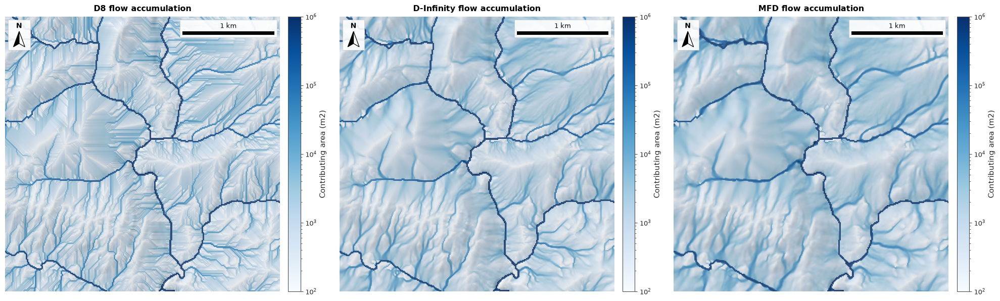

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(20, 6))
for ax, (name, facc_img) in zip(axs, (("D8", facc_d8), ("D-Infinity", facc_dinf),
                                      ("MFD", facc_mfd))):
    rsgispy.mapping.raster.create_shaded_cmap_img_map(
        ax, facc_img, hshade_img, bbox=hill_bbox, title_str=f"{name} flow accumulation",
        cmap_name="Blues", vmin=100, vmax=1e6, use_log_norm=True, hshade_alpha=0.25,
        cbar_label="Contributing area (m2)",
    )
plt.tight_layout()

## 5.3 Flow Length

`flow_length` gives, for every pixel, the length of the flow path in metres: downstream to where the water leaves the DEM (`direction="downstream"`) or the longest flow path upstream of the pixel (`direction="upstream"`). The upstream flow length at a gauge is the length of the catchment's longest flow path, which is used, for example, in formulas for the time of concentration of a catchment. It is read at the gauging stations in section 7.

In [18]:
flow_len_up_img = os.path.join(out_dir, "flow_length_upstream.tif")
rsgispy.elevation.hydrology.flow_length(
    fdir_d8, flow_len_up_img, direction="upstream", use_pbar=False
)

# 6. Stream Network

## 6.1 Extracting the Streams

`extract_streams` marks as a stream every pixel whose contributing area is at least `threshold` (`uint8`: `1` stream, `0` hillslope). With `threshold_units="area"` the threshold is in m².

**Choosing the threshold.** The threshold sets where the channels begin, and so the density of the stream network. There is no single right value: small thresholds (e.g. 1–5 ha) give a dense network including ephemeral gullies, while larger ones (around 0.5–1 km²) give something close to the rivers on a 1:50,000 map. Compare the result with a map or imagery and adjust it. A threshold of 1 km² is used here; it also controls the number and size of the subcatchments (section 7.5) and the HAND values (section 8.1).

In [19]:
stream_threshold = 1e6  # m2 (1 km2)

streams_img = os.path.join(out_dir, "streams.tif")
rsgispy.elevation.hydrology.extract_streams(
    facc_d8, streams_img, threshold=stream_threshold, threshold_units="area",
    use_pbar=False,
)
with rasterio.open(streams_img) as src:
    n_stream_pxls = int(numpy.count_nonzero(src.read(1) == 1))
print(f"{n_stream_pxls} stream pixels")

79880 stream pixels


## 6.2 Stream Links and Order

The other stream functions use the binary stream raster and the D8 flow directions:

* `stream_link` gives each reach (the stretch of stream from a source or a confluence to the next confluence or outlet) a unique ID;
* `stream_order` gives the Strahler order (`method="strahler"`: two streams of order *n* join to make a stream of order *n* + 1, and a smaller stream joining does not change the order) or the Shreve magnitude (`method="shreve"`: the magnitudes add up at each confluence).

In [20]:
links_img = os.path.join(out_dir, "stream_links.tif")
order_img = os.path.join(out_dir, "stream_strahler.tif")
rsgispy.elevation.hydrology.stream_link(streams_img, fdir_d8, links_img, use_pbar=False)
rsgispy.elevation.hydrology.stream_order(
    streams_img, fdir_d8, order_img, method="strahler", use_pbar=False
)
with rasterio.open(links_img) as src:
    print(f"{int(src.read(1).max())} stream reaches")
with rasterio.open(order_img) as src:
    order_arr = src.read(1)
    print(f"Maximum Strahler order: {int(order_arr[order_arr < 255].max())}")

627 stream reaches
Maximum Strahler order: 4


## 6.3 Vector Streams

`vectorise_streams` converts the reaches to lines with the columns `link_id`, `down_link_id` (the reach downstream; `-1` at an outlet), `order` and `length_m` and, given the DEM and the flow accumulation, `elev_start`, `elev_end`, `drop_m`, `slope` (m/m) and `max_acc` (here in m²). Each line ends on the first vertex of the reach downstream of it, so the lines join up and can be used for network analysis.

In [21]:
streams_vec = os.path.join(out_dir, "streams.gpkg")
rsgispy.elevation.hydrology.vectorise_streams(
    streams_img,
    fdir_d8,
    streams_vec,
    dem_img=cond_dem,
    flow_acc_img=facc_d8,
    order_method="strahler",
    use_pbar=False,
)
streams_gdf = geopandas.read_file(streams_vec)
print(f"{len(streams_gdf)} reaches, {streams_gdf['length_m'].sum() / 1000:.0f} km of "
      f"channel; drainage density {streams_gdf['length_m'].sum() / 1000 / (n_vld_pxls * pxl_area / 1e6):.2f} km/km2")
streams_gdf.drop(columns="geometry").head()

627 reaches, 934 km of channel; drainage density 0.72 km/km2


,link_id,down_link_id,order,length_m,elev_start,elev_end,drop_m,slope,max_acc
0,1,-1,3,1119.116882,55.914680,46.411621,9.503059,0.008492,35739400.0
1,2,-1,2,2038.528137,124.965828,89.582214,35.383614,0.017357,9536000.0
2,3,-1,2,746.690476,1.838955,1.261102,0.577853,0.000774,5617300.0
3,4,3,1,14.142136,1.838955,1.838955,0.000000,0.000000,1004200.0
4,5,2,1,1450.121933,188.623276,124.965828,63.657448,0.043898,1804600.0


In [22]:
# Number of reaches, length and mean slope by Strahler order
order_summary = streams_gdf.groupby("order").agg(
    n_reaches=("link_id", "count"),
    length_km=("length_m", lambda x: x.sum() / 1000),
    mean_slope=("slope", "mean"),
)
order_summary.round(3)

,n_reaches,length_km,mean_slope
order,,,
1,340,479.754,0.046
2,163,279.952,0.021
3,120,170.157,0.010
4,4,4.216,0.001


Note that these are counts of *reaches* (links between confluences), not of streams: every time a small tributary joins a third-order river, the river is split into a new reach, which is why there are almost as many third-order reaches as second-order ones. The mean slope of the reaches decreases with the order, as is typical for a river network: steep headwater streams and gentle main rivers. The map below draws each order in its own layer with `create_vec_lyr_map`, with thicker and darker lines for the higher orders, over the hillshade.

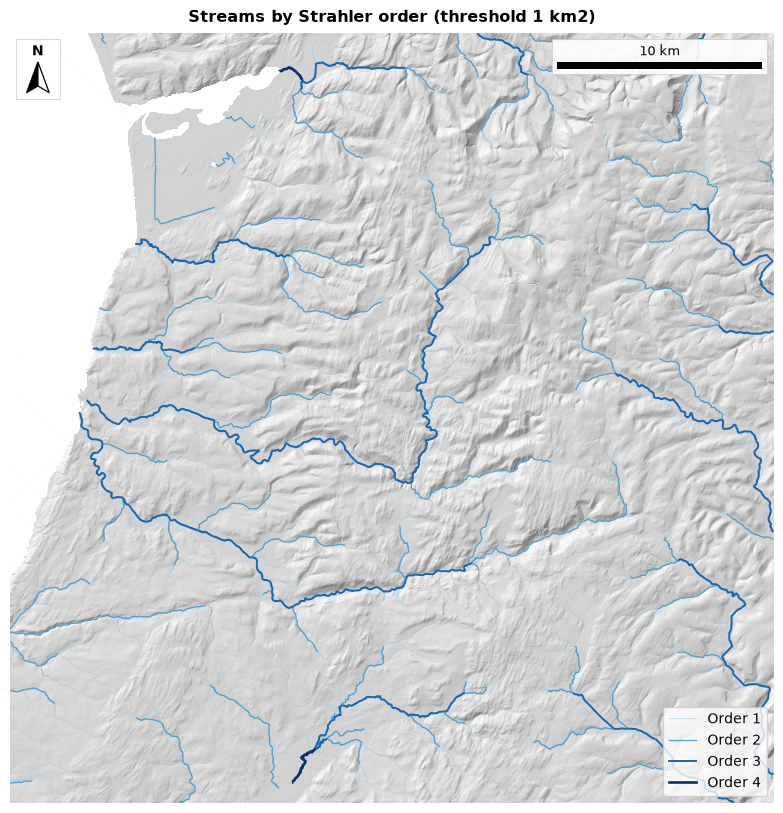

In [23]:
orders = sorted(streams_gdf["order"].unique())
order_clrs = [matplotlib.colormaps["Blues"](0.35 + 0.65 * i / (len(orders) - 1))
              for i in range(len(orders))]
order_clrs = [matplotlib.colors.to_hex(c) for c in order_clrs]

fig, ax = plt.subplots(figsize=(10, 10))
_ = rsgispy.mapping.raster.create_raster_img_map(
    ax, hshade_img, img_bands=[1], img_stch=rsgispy.IMG_STRETCH_LINEAR, bbox=dem_bbox,
    img_alpha=0.6, show_scale_bar=False,
)
_ = rsgispy.mapping.vector.create_vec_lyr_map(
    ax,
    [streams_gdf[streams_gdf["order"] == o] for o in orders],
    dem_bbox,
    title_str="Streams by Strahler order (threshold 1 km2)",
    vec_line_clrs=order_clrs,
    vec_line_widths=[0.4 + 0.5 * i for i in range(len(orders))],
    plot_zorders=[2 + i for i in range(len(orders))],
    show_map_axis=False,
    show_north_arrow=True,
)
_ = ax.legend(
    handles=[matplotlib.lines.Line2D([], [], color=c, lw=0.4 + 0.5 * i, label=f"Order {o}")
             for i, (o, c) in enumerate(zip(orders, order_clrs))],
    loc="lower right",
)

The streams follow the valleys. The Rheidol (from the Nant-y-moch reservoir in the north-east, then south to Devil's Bridge and west to Aberystwyth) and the Ystwyth (from the east, south of the Rheidol) are third-order rivers with this threshold; order 4 is only reached by two short stretches near the northern and southern edges of the DEM. The Strahler order depends on the threshold: a lower threshold adds first-order streams and raises the order of every river downstream of them. In the DEM the Rheidol and the Ystwyth reach the coast a few hundred metres apart; in reality they share the harbour mouth at Aberystwyth. The straight lines on the Cors Fochno bog in the north-west are flow paths across the flat bog surface and its drainage ditches.

## 6.4 Distance to the Stream

`flow_distance` gives, for every pixel, the distance along the flow path to the stream it drains into: horizontally in metres (`distance_type="horizontal"`), or the drop in elevation to the stream (`"vertical"`, which needs the DEM; compare HAND in section 8.1).

In [24]:
dist_to_stream_img = os.path.join(out_dir, "dist_to_stream.tif")
rsgispy.elevation.hydrology.flow_distance(
    fdir_d8, streams_img, dist_to_stream_img, distance_type="horizontal", use_pbar=False
)

## 6.5 Burning Streams into the DEM

When mapped rivers are available (for example the Ordnance Survey's OS Open Rivers, or OpenStreetMap waterways), they can be *burnt* into the DEM before conditioning: the pixels under the river lines are lowered by `burn_depth` metres (and, with `buffer_dist`, the pixels around them are lowered smoothly towards the river; the AGREE method of Hellweger, 1997). This forces the modelled streams onto the mapped ones, which helps on flat floodplains and where the DEM is poor (for example where a river passes under a bridge or through a culvert). It only makes sense if the mapped rivers are accurate and line up with the DEM's valleys; otherwise it creates parallel trenches. `burn_streams` does this on its own, and `condition_dem` does it with its `streams_vec` argument before breaching and filling.

There is no mapped river layer in the tutorial data, so to show how it works the main rivers derived above (Strahler order 3 and above) are burnt into the DEM by 2 m. In a real analysis use an independent river layer: burning a DEM's own streams back into it changes very little.

In [25]:
main_rivers_vec = os.path.join(out_dir, "main_rivers.gpkg")
streams_gdf[streams_gdf["order"] >= 3].to_file(main_rivers_vec)

dem_burnt_img = os.path.join(out_dir, "dem_burnt.tif")
rsgispy.elevation.hydrology.burn_streams(
    dem_img, main_rivers_vec, dem_burnt_img, burn_depth=2.0, use_pbar=False
)
with rasterio.open(dem_burnt_img) as src:
    burn_diff = src.read(1)[vld_dem] - dem_arr[vld_dem]
print(f"{numpy.count_nonzero(burn_diff < -0.001)} pixels lowered, by up to "
      f"{-burn_diff.min():.1f} m")

# The same burning as part of the conditioning:
# rsgispy.elevation.hydrology.condition_dem(
#     dem_img, cond_dem, max_breach_depth=5.0, max_breach_length=30,
#     streams_vec=main_rivers_vec, burn_depth=2.0)

21059 pixels lowered, by up to 2.0 m


# 7. Watersheds and Catchments

There are three ways to divide the DEM into catchments, all from the D8 flow directions:

* `delineate_watersheds`: the area upstream of given pour points, such as river mouths or gauging stations;
* `delineate_basins`: every complete drainage basin (all the pixels that drain to the same outlet on the coast or the edge of the DEM, or into the same sink);
* `delineate_subcatchments`: the area that drains directly into each stream reach.

## 7.1 Pour Points

Pour points are usually a vector file of gauging stations or other points of interest. Here they are created in the notebook from approximate coordinates (read from a map, to the nearest 100 m): the mouths of the Ystwyth, Rheidol and Clarach, and the approximate locations of the Natural Resources Wales gauging stations on the Rheidol at Llanbadarn Fawr and the Ystwyth at Pont Llolwyn, which are upstream of the mouths. Their catchment areas published by the UK National River Flow Archive are about 182 km² and 170 km², which will be used to check the results.

The points need an integer ID column, which becomes the value of each watershed in the output raster.

In [26]:
pour_pts_gdf = geopandas.GeoDataFrame(
    {
        "pt_id": [1, 2, 3, 4, 5],
        "name": ["Ystwyth mouth", "Rheidol mouth", "Clarach mouth",
                 "Rheidol at Llanbadarn Fawr", "Ystwyth at Pont Llolwyn"],
    },
    geometry=geopandas.points_from_xy(
        [257900, 258300, 258600, 260100, 259100],
        [280700, 281300, 283800, 280400, 277400],
    ),
    crs="EPSG:27700",
)
pour_pts_vec = os.path.join(out_dir, "pour_points.gpkg")
pour_pts_gdf.to_file(pour_pts_vec)
pour_pts_gdf

,pt_id,name,geometry
0,1,Ystwyth mouth,POINT (257900 280700)
1,2,Rheidol mouth,POINT (258300 281300)
2,3,Clarach mouth,POINT (258600 283800)
3,4,Rheidol at Llanbadarn Fawr,POINT (260100 280400)
4,5,Ystwyth at Pont Llolwyn,POINT (259100 277400)


## 7.2 Snapping the Pour Points

Coordinates of gauges and outlets are rarely exactly on the modelled stream: a point 20 m from the channel would delineate the catchment of a few hillslope pixels. `snap_pour_points` moves each point to the pixel with the largest flow accumulation within `snap_dist` metres (only stream pixels when `streams_img` is given) and records the distance moved (`snap_dist_m`) and the accumulation at the new position (`snapped_acc`, here in m²).

Choose `snap_dist` with care: about the positional error of the coordinates (here 100 m). Because the point moves to the *largest* accumulation within the radius, a large radius moves points downstream along the river and, near a confluence, can move a point on a tributary onto the main river. Always check `snapped_acc` against the known catchment area.

In [27]:
pour_pts_snap_vec = os.path.join(out_dir, "pour_points_snapped.gpkg")
rsgispy.elevation.hydrology.snap_pour_points(
    pour_pts_vec, facc_d8, pour_pts_snap_vec, snap_dist=100, streams_img=streams_img,
    use_pbar=False,
)
pour_pts_snap_gdf = geopandas.read_file(pour_pts_snap_vec)
pour_pts_snap_gdf["upstream_area_km2"] = pour_pts_snap_gdf["snapped_acc"] / 1e6

# The longest flow path upstream of each point (from section 5.3)
with rasterio.open(flow_len_up_img) as src:
    pt_xy = [(p.x, p.y) for p in pour_pts_snap_gdf.geometry]
    pour_pts_snap_gdf["longest_path_km"] = [v[0] / 1000 for v in src.sample(pt_xy)]
pour_pts_snap_gdf.drop(columns="geometry").round(2)

,pt_id,name,snap_dist_m,snapped_acc,upstream_area_km2,longest_path_km
0,1,Ystwyth mouth,58.31,193253904.0,193.25,47.220001
1,2,Rheidol mouth,28.28,190187600.0,190.19,48.860001
2,3,Clarach mouth,40.00,46677700.0,46.68,15.560000
3,4,Rheidol at Llanbadarn Fawr,100.00,183232496.0,183.23,46.330002
4,5,Ystwyth at Pont Llolwyn,90.55,175405200.0,175.41,41.919998


The areas upstream of the gauging stations are close to the published catchment areas (182 and 170 km²), which shows that the flow routing is working: the Rheidol is within 1% and the Ystwyth within about 3% (the gauge positions used here are approximate, and the published areas were themselves derived from maps or a coarser DEM). The longest flow path above the Rheidol gauge is about 46 km.

## 7.3 Delineating the Watersheds

`delineate_watersheds` labels the pixels that drain to each point, with the values of `id_field`. When the points are nested (one upstream of another, like the gauges and the mouths here) each pixel is given to the nearest point downstream, so the watershed of a river mouth is the **incremental** area between its gauge and the sea. The total area above a point is the sum of its watershed and all the watersheds upstream of it (or its `snapped_acc`).

`polygonise_watersheds` converts the raster to polygons, with the columns `watershed_id`, `area_m2`, `perimeter_m` and, with `dem_img`, `elev_min`, `elev_mean` and `elev_max`. `simplify_tol` simplifies the stair-step pixel edges.

In [28]:
wsheds_img = os.path.join(out_dir, "watersheds.tif")
wsheds_vec = os.path.join(out_dir, "watersheds.gpkg")
rsgispy.elevation.hydrology.delineate_watersheds(
    fdir_d8, pour_pts_snap_vec, wsheds_img, id_field="pt_id", use_pbar=False
)
rsgispy.elevation.hydrology.polygonise_watersheds(
    wsheds_img, wsheds_vec, dem_img=cond_dem, simplify_tol=10, use_pbar=False
)
wsheds_gdf = geopandas.read_file(wsheds_vec)
wsheds_gdf = wsheds_gdf.merge(
    pour_pts_gdf[["pt_id", "name"]], left_on="watershed_id", right_on="pt_id"
).drop(columns="pt_id")
wsheds_gdf["area_km2"] = wsheds_gdf["area_m2"] / 1e6
wsheds_gdf.drop(columns="geometry").round(1)

,watershed_id,area_m2,perimeter_m,elev_min,elev_mean,elev_max,name,area_km2
0,1,17853300.0,28470.5,0.0,98.4,203.0,Ystwyth mouth,17.9
1,2,6954200.0,14851.3,0.0,55.4,156.9,Rheidol mouth,7.0
2,3,46682450.0,40933.3,0.0,140.0,437.8,Clarach mouth,46.7
3,4,183226050.0,108644.3,3.2,343.1,750.4,Rheidol at Llanbadarn Fawr,183.2
4,5,175405700.0,106377.3,11.6,261.7,610.5,Ystwyth at Pont Llolwyn,175.4


The two gauged watersheds are large upland catchments, while the watersheds of the Rheidol and Ystwyth mouths are only the few km² between the gauges and the sea. Adding them up gives the total area of each river:

In [29]:
ws_area = wsheds_gdf.set_index("watershed_id")["area_km2"]
print(f"Rheidol: {ws_area[4]:.1f} + {ws_area[2]:.1f} = {ws_area[4] + ws_area[2]:.1f} km2")
print(f"Ystwyth: {ws_area[5]:.1f} + {ws_area[1]:.1f} = {ws_area[5] + ws_area[1]:.1f} km2")

Rheidol: 183.2 + 7.0 = 190.2 km2
Ystwyth: 175.4 + 17.9 = 193.3 km2


## 7.4 Tracing Flow Paths

`trace_flow_path` traces lines from points:

* downstream to where the water leaves the DEM (`direction="downstream"`), for example the path a pollutant would take from a spill site;
* upstream along the largest flow accumulation (`direction="upstream"`, which needs `flow_acc_img`): the main stem of the river above each point, with its length (`path_length_m`).

The downstream path is traced from a point near the summit of Pumlumon Fawr, and the main stems are traced upstream from the two gauging stations.

In [30]:
start_pt_gdf = geopandas.GeoDataFrame(
    {"pt_id": [1], "name": ["Pumlumon Fawr"]},
    geometry=geopandas.points_from_xy([278900], [286800]),
    crs="EPSG:27700",
)
start_pt_vec = os.path.join(out_dir, "flow_path_start.gpkg")
start_pt_gdf.to_file(start_pt_vec)

down_path_vec = os.path.join(out_dir, "flow_path_downstream.gpkg")
rsgispy.elevation.hydrology.trace_flow_path(
    fdir_d8, start_pt_vec, down_path_vec, direction="downstream", use_pbar=False
)
down_path_gdf = geopandas.read_file(down_path_vec)

# Only the two gauges (pt_id 4 and 5)
gauges_vec = os.path.join(out_dir, "gauges_snapped.gpkg")
pour_pts_snap_gdf[pour_pts_snap_gdf["pt_id"] >= 4].to_file(gauges_vec)
main_stems_vec = os.path.join(out_dir, "gauge_main_stems.gpkg")
rsgispy.elevation.hydrology.trace_flow_path(
    fdir_d8, gauges_vec, main_stems_vec, direction="upstream", flow_acc_img=facc_d8,
    use_pbar=False,
)
main_stems_gdf = geopandas.read_file(main_stems_vec)

print(f"Downstream path from Pumlumon Fawr: {down_path_gdf['path_length_m'].iloc[0] / 1000:.1f} km")
main_stems_gdf[["pt_id", "name", "path_length_m"]].round(0)

Downstream path from Pumlumon Fawr: 42.3 km


,pt_id,name,path_length_m
0,4,Rheidol at Llanbadarn Fawr,46266.0
1,5,Ystwyth at Pont Llolwyn,41773.0


The map shows the watersheds, the stream network, the snapped pour points and the traced paths. The flow path from Pumlumon Fawr runs down into the Rheidol and follows it past the Nant-y-moch reservoir, Ponterwyd and Devil's Bridge to the sea at Aberystwyth. The main stems traced upstream from the gauges follow the largest tributary at each confluence, so the Rheidol's ends in the headwaters north of Nant-y-moch rather than at Llyn Llygad Rheidol, the traditional source.

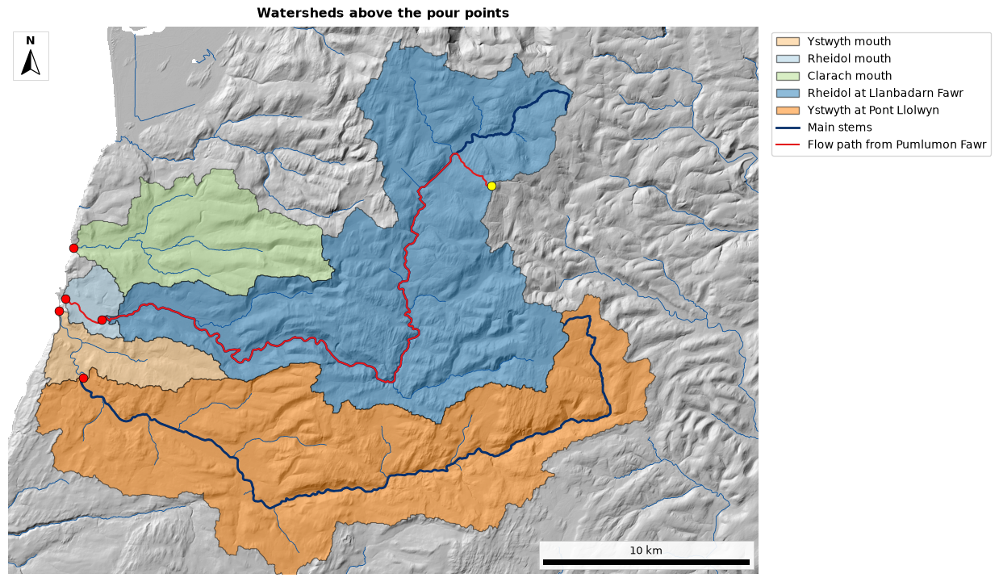

In [31]:
ws_clrs = ["#fdbf6f", "#a6cee3", "#b2df8a", "#1f78b4", "#ff7f00"]
ws_bbox = [255500, 291830, 268000, 294500]

fig, ax = plt.subplots(figsize=(12, 9))
_ = rsgispy.mapping.raster.create_raster_img_map(
    ax, hshade_img, img_bands=[1], img_stch=rsgispy.IMG_STRETCH_LINEAR, bbox=ws_bbox,
    show_scale_bar=False,
)
_ = rsgispy.mapping.vector.create_vec_lyr_map(
    ax,
    [wsheds_gdf[wsheds_gdf["watershed_id"] == i] for i in wsheds_gdf["watershed_id"]],
    ws_bbox,
    vec_fill_clrs=[ws_clrs[i - 1] for i in wsheds_gdf["watershed_id"]],
    vec_line_clrs="black",
    vec_line_widths=0.8,
    vec_fill_alphas=0.5,
    plot_zorders=2,
    show_scale_bar=False,
)
_ = rsgispy.mapping.vector.create_vec_lyr_map(
    ax,
    [streams_gdf[streams_gdf["order"] >= 2], main_stems_gdf, down_path_gdf,
     pour_pts_snap_gdf, start_pt_gdf],
    ws_bbox,
    title_str="Watersheds above the pour points",
    vec_fill_clrs=["none", "none", "none", "red", "yellow"],
    vec_line_clrs=["#08519c", "#08306b", "#e31a1c", "black", "black"],
    vec_line_widths=[0.6, 2.0, 1.5, 0.5, 0.5],
    vec_markersize=60,
    plot_zorders=[3, 4, 5, 6, 6],
    show_map_axis=False,
    show_north_arrow=True,
    scale_bar_loc="lower right",
)
_ = ax.legend(
    handles=[matplotlib.patches.Patch(facecolor=ws_clrs[i - 1], alpha=0.5, edgecolor="k",
                                      label=n)
             for i, n in zip(wsheds_gdf["watershed_id"], wsheds_gdf["name"])]
    + [matplotlib.lines.Line2D([], [], color="#08306b", lw=2, label="Main stems"),
       matplotlib.lines.Line2D([], [], color="#e31a1c", lw=1.5,
                               label="Flow path from Pumlumon Fawr")],
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
)

## 7.5 Drainage Basins and Subcatchments

`delineate_basins` needs only the flow directions: it labels every pixel with the outlet it drains to. Many of the basins are tiny (a single coastal or edge pixel draining straight out of the DEM), so the largest basins are listed. Note that basins cut by the edge of the DEM, such as those of the Dyfi and the upper Wye and Severn east of Pumlumon, are incomplete: a catchment can only be delineated if the DEM covers all of it.

In [32]:
basins_img = os.path.join(out_dir, "basins.tif")
rsgispy.elevation.hydrology.delineate_basins(fdir_d8, basins_img, use_pbar=False)

with rasterio.open(basins_img) as src:
    basins_arr = src.read(1)
basin_ids, basin_counts = numpy.unique(basins_arr[basins_arr > 0], return_counts=True)
print(f"{len(basin_ids)} basins; {numpy.count_nonzero(basin_counts * pxl_area > 1e6)} "
      "are larger than 1 km2")
basin_areas = pandas.Series(basin_counts * pxl_area / 1e6, index=basin_ids,
                            name="area_km2").sort_values(ascending=False)
basin_areas.head(8).round(1)

2394 basins; 53 are larger than 1 km2


1447    193.3
1403    190.2
1798     88.9
1793     80.7
2394     70.6
1644     70.6
1098     53.1
1197     49.5
Name: area_km2, dtype: float64

`delineate_subcatchments` labels the area that drains directly into each stream reach (from `stream_link`), not through another reach. Subcatchments are the units used by semi-distributed hydrological models. They are polygonised below and mapped for the Rheidol and Ystwyth.

In [33]:
subcatch_img = os.path.join(out_dir, "subcatchments.tif")
subcatch_vec = os.path.join(out_dir, "subcatchments.gpkg")
rsgispy.elevation.hydrology.delineate_subcatchments(
    fdir_d8, links_img, subcatch_img, use_pbar=False
)
rsgispy.elevation.hydrology.polygonise_watersheds(
    subcatch_img, subcatch_vec, dem_img=cond_dem, use_pbar=False
)
subcatch_gdf = geopandas.read_file(subcatch_vec)
print(f"{len(subcatch_gdf)} subcatchments; median area "
      f"{subcatch_gdf['area_m2'].median() / 1e6:.2f} km2")

627 subcatchments; median area 1.61 km2


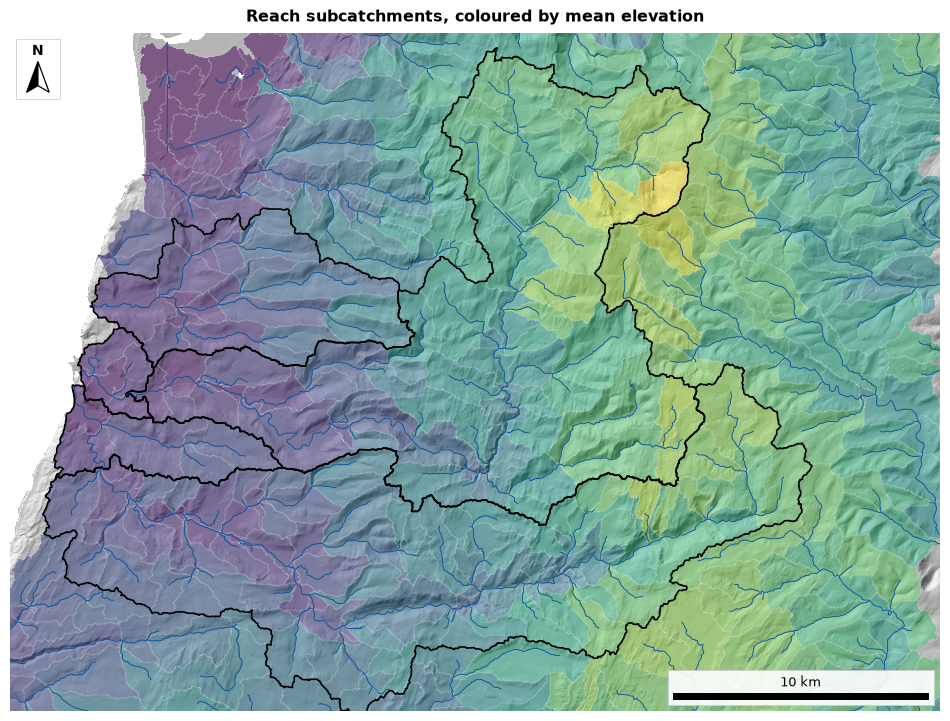

In [34]:
fig, ax = plt.subplots(figsize=(12, 9))
_ = rsgispy.mapping.raster.create_raster_img_map(
    ax, hshade_img, img_bands=[1], img_stch=rsgispy.IMG_STRETCH_LINEAR, bbox=ws_bbox,
    show_scale_bar=False,
)
_ = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax,
    subcatch_gdf,
    "elev_mean",
    ws_bbox,
    vec_fill_cmap="viridis",
    vec_line_clr="white",
    vec_line_width=0.2,
    vec_fill_alpha=0.5,
    plot_zorder=2,
    show_scale_bar=False,
)
_ = rsgispy.mapping.vector.create_vec_lyr_map(
    ax,
    [wsheds_gdf, streams_gdf],
    ws_bbox,
    title_str="Reach subcatchments, coloured by mean elevation",
    vec_fill_clrs=["none", "none"],
    vec_line_clrs=["black", "#08519c"],
    vec_line_widths=[1.2, 0.6],
    plot_zorders=[3, 4],
    show_map_axis=False,
    show_north_arrow=True,
    scale_bar_loc="lower right",
)

# 8. Terrain Indices

## 8.1 Height Above Nearest Drainage (HAND)

HAND (Nobre et al., 2011) is, for every pixel, its height above the stream pixel it drains to along the D8 flow path. `calc_hand` writes it in metres (`0` on the streams). Low values mark the valley floors, which flood when the river rises; high values mark the hillslopes and terraces, which do not. Unlike the elevation, HAND is relative to the local river, so a valley floor in the uplands has the same low values as one near the sea.

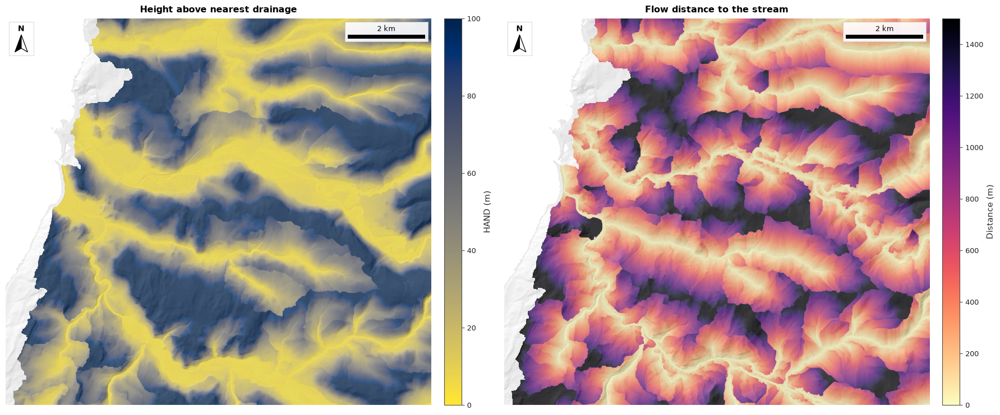

In [35]:
hand_img = os.path.join(out_dir, "hand.tif")
rsgispy.elevation.hydrology.calc_hand(cond_dem, fdir_d8, streams_img, hand_img,
                                      use_pbar=False)

# A zoom over the lower Rheidol and Ystwyth valleys and Aberystwyth.
aber_bbox = [256500, 267500, 274500, 284500]

fig, axs = plt.subplots(1, 2, figsize=(18, 7.5))
rsgispy.mapping.raster.create_shaded_cmap_img_map(
    axs[0], hand_img, hshade_img, bbox=aber_bbox, title_str="Height above nearest drainage",
    cmap_name="cividis_r", vmin=0, vmax=100, hshade_alpha=0.3, cbar_label="HAND (m)",
)
rsgispy.mapping.raster.create_shaded_cmap_img_map(
    axs[1], dist_to_stream_img, hshade_img, bbox=aber_bbox,
    title_str="Flow distance to the stream", cmap_name="magma_r", vmin=0, vmax=1500,
    hshade_alpha=0.3, cbar_label="Distance (m)",
)
plt.tight_layout()

## 8.2 A Flood Inundation Scenario

`flood_inundation_from_hand` turns HAND into a flood depth for a water level (stage) `h` above the channel: `depth = max(0, h - HAND)`. The stage can be a single value or a raster of stages (for example interpolated along the river from gauges). Running it for several stages and measuring the flooded area gives a stage–area curve for the valleys.

This is a simple "bathtub along the river" model: it does not account for the volume of water, embankments that protect the floodplain, or the tide, and it depends on the stream threshold (smaller streams would add flooding along them). Use it for screening and first estimates, not as a replacement for a hydraulic model.

In [36]:
flood_stats = []
for stage in [1, 2, 3, 5]:
    depth_img = os.path.join(out_dir, f"flood_depth_{stage}m.tif")
    rsgispy.elevation.hydrology.flood_inundation_from_hand(
        hand_img, depth_img, water_depth=stage, use_pbar=False
    )
    with rasterio.open(depth_img) as src:
        depth = src.read(1)
        depth = depth[(depth != src.nodata) & vld_dem]
    flood_stats.append({"stage_m": stage,
                        "flooded_km2": numpy.count_nonzero(depth > 0) * pxl_area / 1e6,
                        "mean_depth_m": depth[depth > 0].mean()})
flood_stats = pandas.DataFrame(flood_stats).set_index("stage_m")
flood_stats.round(2)

,flooded_km2,mean_depth_m
stage_m,,
1,49.72,0.68
2,79.37,1.24
3,102.09,1.86
5,134.52,3.18


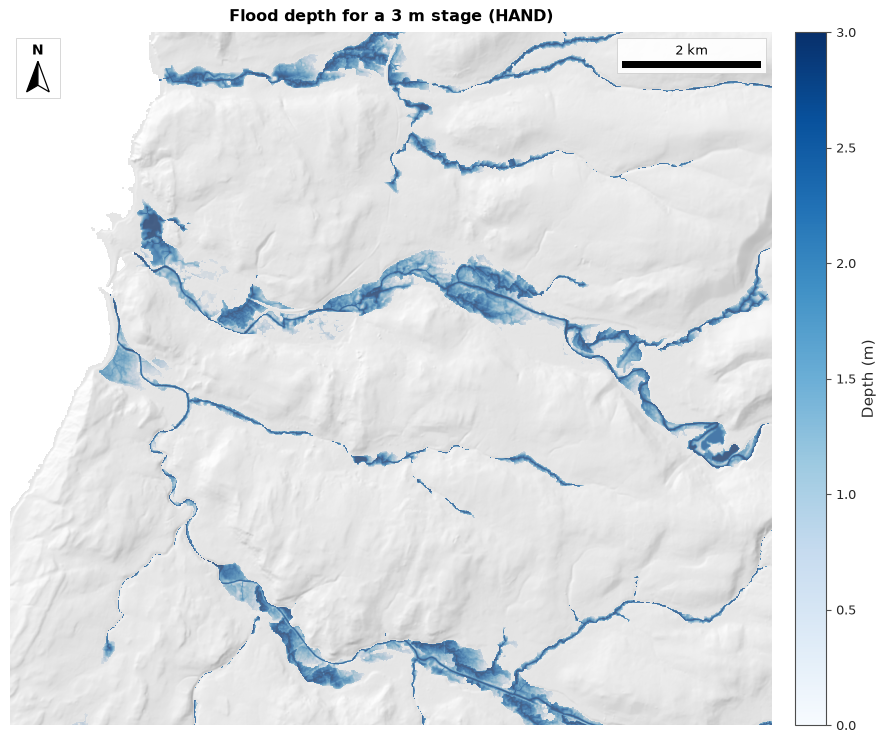

In [37]:
# Map the 3 m scenario: the dry pixels (depth 0) are set to no data so the
# hillshade shows through.
depth_img = os.path.join(out_dir, "flood_depth_3m.tif")
depth_disp_img = os.path.join(out_dir, "flood_depth_3m_display.tif")
rsgispy.imagecalc.maths.band_maths(
    depth_disp_img,
    "depth > 0 ? depth : -1",
    [BandDefn("depth", depth_img, 1)],
    datatype=rsgispy.TYPE_32FLOAT,
    no_data_val=-1,
    use_pbar=False,
)

fig, ax = plt.subplots(figsize=(10, 9))
img = rsgispy.mapping.raster.create_shaded_cmap_img_map(
    ax, depth_disp_img, hshade_img, bbox=aber_bbox,
    title_str="Flood depth for a 3 m stage (HAND)", cmap_name="Blues", vmin=0, vmax=3,
    hshade_alpha=0.35, cbar_label="Depth (m)",
)

The flooding is confined to the valley floors of the Rheidol and Ystwyth (and their tributaries), and spreads where the valleys are wide and flat, such as the lower Rheidol valley east of Aberystwyth.

## 8.3 TWI, SPI and the LS Factor

Three indices combine the upslope area with the local slope β:

* the **topographic wetness index**, TWI = ln(a / tan β) (`calc_twi`): where water accumulates and soils stay wet. Values of 2–8 are typical on hillslopes and above 10 on valley floors;
* the **stream power index**, SPI = a tan β (`calc_spi`): the erosive power of flowing water (gullies and channel heads). It is very skewed, so it is mapped with a logarithmic scale;
* the RUSLE **slope length and steepness factor**, LS = (m + 1) (a / 22.13)^m (sin β / 0.0896)^n (`calc_ls_factor`), used with the other RUSLE factors to estimate soil loss (defaults m = 0.4 and n = 1.3).

All three use the **specific catchment area** *a*: the upslope area per unit width of contour (m²/m), not the contributing area. It is the contributing area in m² divided by the width the flow crosses, taken as the pixel size, and is calculated with `band_maths`. Passing the flow accumulation itself raises an exception. The MFD accumulation is used here (`idx_facc`): with D8, *a* jumps from pixel to pixel on hillslopes and the indices are noisy. The D-Infinity accumulation can be used instead (set `idx_facc = facc_dinf`); it gives narrower lines of high values along the hollows than MFD. The slope comes from `rsgispy.elevation.terrain.slope` on the conditioned DEM.

In [38]:
slope_img = os.path.join(out_dir, "slope_deg.tif")
sca_img = os.path.join(out_dir, "sca.tif")
twi_img = os.path.join(out_dir, "twi.tif")
spi_img = os.path.join(out_dir, "spi.tif")
ls_img = os.path.join(out_dir, "ls_factor.tif")

rsgispy.elevation.terrain.slope(cond_dem, slope_img, unit="degrees", use_pbar=False)

# The flow accumulation used for the indices: MFD (or facc_dinf for D-Infinity).
idx_facc = facc_mfd

# Specific catchment area (m2/m): contributing area / contour width (pixel size).
acc_no_data = rsgispy.imageutils.metadata.get_img_no_data_value(idx_facc)
rsgispy.imagecalc.maths.band_maths(
    sca_img,
    f"acc == {acc_no_data} ? {acc_no_data} : acc / {x_res}",
    [BandDefn("acc", idx_facc, 1)],
    datatype=rsgispy.TYPE_32FLOAT,
    no_data_val=acc_no_data,
    use_pbar=False,
)

rsgispy.elevation.hydrology.calc_twi(sca_img, slope_img, twi_img, slope_units="degrees",
                                     min_slope=0.001, use_pbar=False)
rsgispy.elevation.hydrology.calc_spi(sca_img, slope_img, spi_img, slope_units="degrees",
                                     use_pbar=False)
rsgispy.elevation.hydrology.calc_ls_factor(sca_img, slope_img, ls_img,
                                           slope_units="degrees", m=0.4, n=1.3,
                                           use_pbar=False)

for name, idx_img in (("TWI", twi_img), ("SPI", spi_img), ("LS", ls_img)):
    i_min, i_max, i_mean, _ = rsgispy.imagecalc.stats.calc_basic_img_band_stats(
        idx_img, use_pbar=False
    )
    print(f"{name}: {i_min[0]:.2f} to {i_max[0]:.2f} (mean {i_mean[0]:.2f})")

TWI: 2.45 to 23.67 (mean 7.31)
SPI: 0.00 to 5501414.00 (mean 570.69)


LS: 0.00 to 2413.56 (mean 9.17)


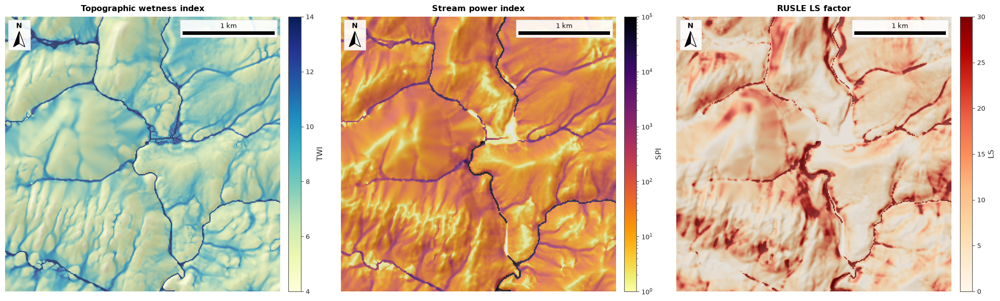

In [39]:
fig, axs = plt.subplots(1, 3, figsize=(20, 6))
for ax, (idx_img, title, cmap_name, vmin, vmax, log, label) in zip(axs, (
    (twi_img, "Topographic wetness index", "YlGnBu", 4, 14, False, "TWI"),
    (spi_img, "Stream power index", "inferno_r", 1, 1e5, True, "SPI"),
    (ls_img, "RUSLE LS factor", "OrRd", 0, 30, False, "LS"),
)):
    rsgispy.mapping.raster.create_shaded_cmap_img_map(
        ax, idx_img, hshade_img, bbox=hill_bbox, title_str=title, cmap_name=cmap_name,
        vmin=vmin, vmax=vmax, use_log_norm=log, hshade_alpha=0.3, cbar_label=label,
    )
plt.tight_layout()

In the upper Rheidol valley the TWI is highest on the valley floor and in the hollows at the heads of the streams, the SPI is highest along the channels on the steep valley sides, and the LS factor is highest on the long, steep valley sides (and in the steep channels), where soil loss would be greatest for the same rainfall, soil and land cover. The white area in the SPI map is the flat surface of the Dinas reservoir, where the slope, and so the SPI, is zero.

# 9. Summary

This notebook has worked through a complete hydrological analysis of a DEM with `rsgispy.elevation.hydrology`:

* the sea was set to no data so the rivers drain to the coast;
* the DEM was conditioned by breaching short, shallow obstructions and filling the rest (`condition_dem`), which changed far fewer pixels than filling alone and kept the cuts within limits chosen for the barriers in the landscape;
* D8 flow directions were used for the streams and catchments, and MFD for the terrain indices;
* the stream network (1 km² threshold) was ordered and vectorised; the watersheds above the Rheidol and Ystwyth gauging stations (about 183 and 175 km²) agree well with the published catchment areas;
* HAND gave a quick first estimate of the areas that would flood for several water levels, and TWI, SPI and LS mapped the wet and erosion-prone parts of the landscape.

The run time of the notebook is printed below.

In [40]:
print(f"Notebook run time: {(time.time() - nb_start_time) / 60:.1f} minutes")

Notebook run time: 1.8 minutes


# 10. Things to Try

* Change the stream threshold (`stream_threshold`), e.g. to 0.1 km² and 5 km², and compare the number of reaches, the maximum Strahler order, the subcatchments and the HAND flood extents. Which threshold gives a network closest to the rivers on an Ordnance Survey map?
* Condition the DEM with `method="fill"` only (or with different `max_breach_depth` and `max_breach_length`) and compare the streams on the Cors Fochno bog.
* Download the OS Open Rivers dataset for the area and burn it into the DEM with `condition_dem(..., streams_vec=...)`. Does it change where the Rheidol and Ystwyth reach the coast?
* Move the gauges further from the rivers or increase `snap_dist` and see how the snapped positions and the watershed areas change.
* Use `stream_order` with `method="shreve"` and compare it with the Strahler order.
* Add more pour points (e.g. the Nant-y-moch dam at about (276500, 286500)) and look at the nested watersheds.
* Summarise the slope, TWI or flood depth for each subcatchment with `rsgispy.zonalstats.labels.calc_label_zonal_stats`, using the subcatchment raster as the labels.
* Calculate the TWI from the D-Infinity accumulation (`idx_facc = facc_dinf`) and from the D8 accumulation; compare the patterns on the hillslopes with the MFD version. Try different values of `mfd_exponent` too.
* Trace the downstream flow paths from a set of random points (`rsgispy.vector.create` has functions to create random points) and map where they reach the sea.

# References

* Barnes, R., Lehman, C., Mulla, D. (2014). Priority-flood: An optimal depression-filling and watershed-labeling algorithm for digital elevation models. *Computers & Geosciences*, 62, 117–127.
* Barnes, R., Lehman, C., Mulla, D. (2014). An efficient assignment of drainage direction over flat surfaces in raster digital elevation models. *Computers & Geosciences*, 62, 128–135.
* Hellweger, F. (1997). AGREE — DEM surface reconditioning system. University of Texas.
* Lindsay, J. B. (2016). Efficient hybrid breaching-filling sink removal methods for flow path enforcement in digital elevation models. *Hydrological Processes*, 30(6), 846–857.
* Moore, I. D., Burch, G. J. (1986). Physical basis of the length-slope factor in the Universal Soil Loss Equation. *Soil Science Society of America Journal*, 50(5), 1294–1298.
* Nobre, A. D., et al. (2011). Height Above the Nearest Drainage — a hydrologically relevant new terrain model. *Journal of Hydrology*, 404(1–2), 13–29.
* Quinn, P., Beven, K., Chevallier, P., Planchon, O. (1991). The prediction of hillslope flow paths for distributed hydrological modelling using digital terrain models. *Hydrological Processes*, 5(1), 59–79.
* Tarboton, D. G. (1997). A new method for the determination of flow directions and upslope areas in grid digital elevation models. *Water Resources Research*, 33(2), 309–319.